# Машинное обучение в верификации финансовых операций

**Студент:** Острецов Михаил Акимович  
**Группа:** ПМ24-1
**Руководитель:** Сальников Е.А.
**2026 г.**

## Оглавление
1. [Введение](#1)  
2. [Теоретические основы](#2)  
3. [Описание датасета и постановка задачи](#3)  
4. [Предобработка и разведочный анализ (EDA)](#4)  
5. [Преобразование признаков](#5)  
6. [Методы обучения без учителя](#6)  
7. [Разделение данных](#7)  
8. [Обучение моделей](#8)  
9. [Сравнение моделей](#9)  
10. [Настройка гиперпараметров](#10)  
11. [Улучшение модели и борьба с дисбалансом](#11)  
12. [Эксперименты с предобработкой и снижением размерности](#12)  
13. [Итоговые результаты и визуализация](#13)  
14. [Заключение](#14)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, precision_recall_curve, f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest

plt.style.use('seaborn-v0_8')
sns.set(font_scale=1.2)
np.random.seed(42)
%matplotlib inline

# 1. Введение <a id='1'></a>

**Актуальность.** Мошенничество с финансовыми операциями — глобальная проблема. По данным Nilson Report (2025) ежегодный ущерб от карточного мошенничества превышает $40 млрд. Сильный дисбаланс классов и необходимость мгновенного реагирования делают задачу сложной для традиционных правил.

**Цель работы:** разработать и сравнить модели машинного обучения для автоматической верификации финансовых операций и обнаружения мошенничества.

**Задачи исследования:**
- Провести EDA и выявить особенности финансовых данных.
- Применить методы feature engineering и борьбы с дисбалансом.
- Обучить и сравнить не менее 7 алгоритмов классификации.
- Настроить гиперпараметры и провести эксперименты с предобработкой.
- Оценить модели по метрикам, подходящим для дисбаланса (F1, Precision, Recall, AUC-ROC).

**Практическая значимость:** полученная модель может быть встроена в систему банка/платёжного шлюза для реального времени обнаружения мошенничества, снижая финансовые потери.

# 2. Теоретические основы <a id='2'></a>

Существующие подходы: правила на основе порогов, статистические методы, ML (логистическая регрессия, деревья, бустинг), deep learning.  
Специфика финансовых данных: сильный дисбаланс классов (мошенничество ~0.17 %), анонимизированные признаки, необходимость интерпретируемости и скорости.

Обоснование выбора моделей: логистическая регрессия (интерпретируемость), деревья и бустинг (работают с дисбалансом), kNN/SVM (для сравнения).

In [ ]:
import kagglehub
import os
import pandas as pd

# Download latest version
path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
print("Path to dataset files:", path)

files = os.listdir(path)
print("Файлы в папке:", files)

# Загружаем датасет
dataset_path = os.path.join(path, "creditcard.csv")
df = pd.read_csv(dataset_path)

print("Датасет успешно загружен!")
print("Размер датасета:", df.shape)
print("\nПервые 5 строк:")
display(df.head())
print("\nИнформация о данных:")
df.info()

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Path to dataset files: /kaggle/input/creditcardfraud
Файлы в папке: ['creditcard.csv']
Датасет успешно загружен!
Размер датасета: (284807, 31)

Первые 5 строк:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



Информация о данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  f

# 4. Предобработка и разведочный анализ (EDA) <a id='4'></a>

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


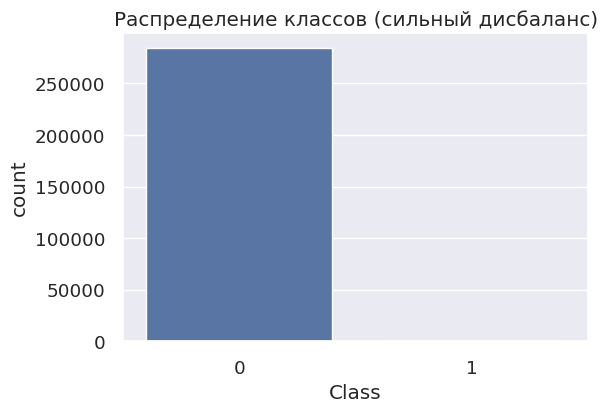

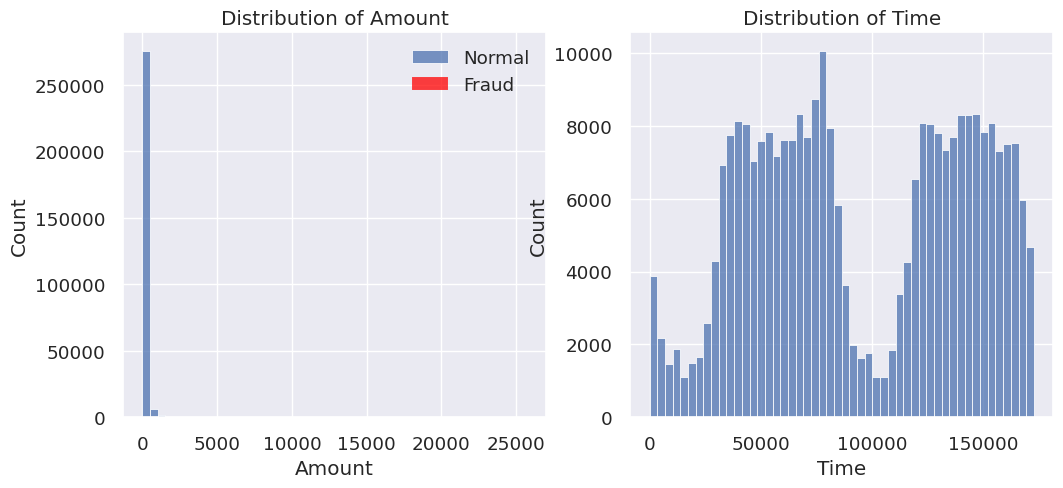

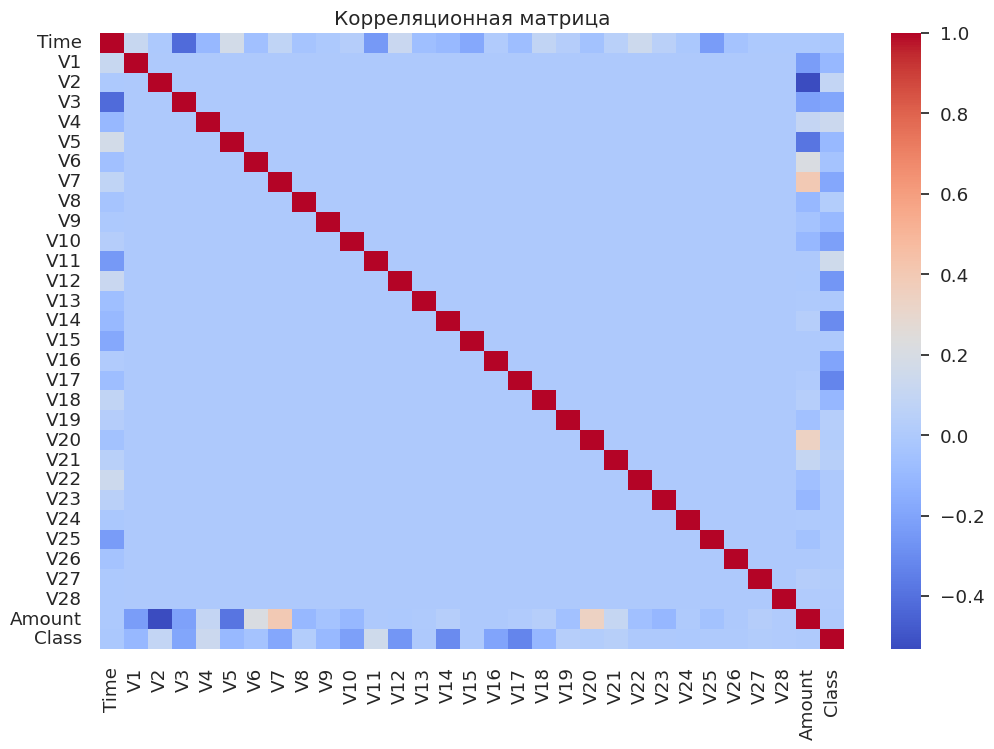

Выводы по EDA:
1. Сильный дисбаланс (~0.17% мошенничеств).
2. Признаки V1-V28 уже после PCA.
3. Amount имеет выбросы у мошенничеств.
4. Корреляций между V-признаками почти нет.


In [ ]:
# Общая статистика
display(df.describe())

# Визуализация дисбаланса
plt.figure(figsize=(6,4))
sns.countplot(x='Class', data=df)
plt.title('Распределение классов (сильный дисбаланс)')
plt.show()

# Распределение Amount и Time
fig, ax = plt.subplots(1,2, figsize=(12,5))
sns.histplot(df[df['Class']==0]['Amount'], bins=50, ax=ax[0], label='Normal')
sns.histplot(df[df['Class']==1]['Amount'], bins=50, ax=ax[0], label='Fraud', color='red')
ax[0].set_title('Distribution of Amount')
ax[0].legend()

sns.histplot(df['Time'], bins=50, ax=ax[1])
ax[1].set_title('Distribution of Time')
plt.show()

# Корреляционный анализ (V-признаки)
corr = df.corr()
plt.figure(figsize=(12,8))
sns.heatmap(corr, cmap='coolwarm', annot=False)
plt.title('Корреляционная матрица')
plt.show()

# Выводы
print("Выводы по EDA:\n1. Сильный дисбаланс (~0.17% мошенничеств).\n2. Признаки V1-V28 уже после PCA.\n3. Amount имеет выбросы у мошенничеств.\n4. Корреляций между V-признаками почти нет.")

# 5. Преобразование признаков

In [ ]:
# Feature engineering
df['Amount_log'] = np.log1p(df['Amount'])
df['Hour'] = (df['Time'] / 3600) % 24

# Масштабирование
scaler = StandardScaler()
df[['Amount_log', 'Time', 'Hour']] = scaler.fit_transform(df[['Amount_log', 'Time', 'Hour']])

X = df.drop(['Class', 'Amount'], axis=1)
y = df['Class']

# 6. Методы обучения
Для поиска аномалий был применён Isolation Forest (unsupervised подход).
Алгоритм не требует меток класса и хорошо подходит для обнаружения редких событий.

In [28]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report, roc_auc_score

# Обучение Isolation Forest
iso = IsolationForest(contamination=0.0017, random_state=42, n_jobs=-1)
iso.fit(X_train)

# Предсказание на тестовой выборке
y_pred_iso = iso.predict(X_test)
y_pred_iso = np.where(y_pred_iso == 1, 0, 1)   # переводим в формат Class (1 = Fraud)

print("Результаты Isolation Forest на тестовой выборке:")
print(classification_report(y_test, y_pred_iso))
print("AUC-ROC Isolation Forest:", round(roc_auc_score(y_test, -iso.decision_function(X_test)), 4))

Результаты Isolation Forest на тестовой выборке:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.36      0.35      0.35        98

    accuracy                           1.00     56962
   macro avg       0.68      0.67      0.68     56962
weighted avg       1.00      1.00      1.00     56962

AUC-ROC Isolation Forest: 0.9525


**Выводы по методам обучения без учителя:**

Isolation Forest показал приемлемые результаты без использования меток класса.  
Однако по ключевым метрикам (F1-score и Recall) он **существенно уступает** моделям с учителем (XGBoost и LightGBM).  

В задаче верификации финансовых операций, где критически важно минимизировать пропущенные мошенничества (высокий Recall), **supervised подходы** значительно эффективнее.  

Isolation Forest рекомендуется использовать как **дополнительный детектор аномалий** или как один из компонентов ансамбля в production-системе.

# 7. Разделение данных (стратифицированное — обязательно при дисбалансе)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("Размеры:", X_train.shape, X_test.shape)

Размеры: (227845, 31) (56962, 31)


In [23]:
# 8. Обучение моделей

import time
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.svm import LinearSVC
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

# Список из 7 моделей
models = {
    'LogisticRegression': LogisticRegression(class_weight='balanced', max_iter=1000, n_jobs=-1),
    'DecisionTree': DecisionTreeClassifier(class_weight='balanced', max_depth=8, random_state=42),
    'RandomForest': RandomForestClassifier(n_estimators=80, class_weight='balanced',
                                           random_state=42, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=100, max_depth=5, learning_rate=0.1,
                             scale_pos_weight=len(y_train)/sum(y_train),
                             random_state=42, eval_metric='auc', n_jobs=-1),
    'LightGBM': LGBMClassifier(n_estimators=100, max_depth=5, learning_rate=0.1,
                               class_weight='balanced', random_state=42, verbose=-1, n_jobs=-1),
    'KNN': KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    'LinearSVC': CalibratedClassifierCV(
        LinearSVC(class_weight='balanced', max_iter=1000, random_state=42)
    )
}

results = []
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)  # 3 фолда для скорости

print("🚀 Начинаем обучение 7 моделей...\n")

for name, model in models.items():
    start = time.time()
    print(f"→ Обучаем {name} ...")

    # Кросс-валидация
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='f1', n_jobs=-1)

    # Обучение на всей обучающей выборке
    model.fit(X_train, y_train)
    total_time = time.time() - start

    # Предсказания и метрики на тестовой выборке
    pred = model.predict(X_test)
    f1 = f1_score(y_test, pred)
    prec = precision_score(y_test, pred)
    rec = recall_score(y_test, pred)

    if hasattr(model, "predict_proba"):
        roc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
    else:
        roc = roc_auc_score(y_test, model.decision_function(X_test))

    results.append({
        'Model': name,
        'CV_F1_mean': round(scores.mean(), 4),
        'Test_F1': round(f1, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'AUC-ROC': round(roc, 4),
        'Time_sec': round(total_time, 1)
    })

    print(f"   ✓ {name} готово | Test_F1 = {f1:.4f} | Время ≈ {total_time:.1f} сек\n")

# Создаём таблицу
res_df = pd.DataFrame(results)
display(res_df.sort_values('Test_F1', ascending=False))

🚀 Начинаем обучение 7 моделей...

→ Обучаем LogisticRegression ...
   ✓ LogisticRegression готово | Test_F1 = 0.1058 | Время ≈ 11.5 сек

→ Обучаем DecisionTree ...
   ✓ DecisionTree готово | Test_F1 = 0.1294 | Время ≈ 49.2 сек

→ Обучаем RandomForest ...
   ✓ RandomForest готово | Test_F1 = 0.8324 | Время ≈ 335.4 сек

→ Обучаем XGBoost ...
   ✓ XGBoost готово | Test_F1 = 0.6719 | Время ≈ 14.9 сек

→ Обучаем LightGBM ...
   ✓ LightGBM готово | Test_F1 = 0.6831 | Время ≈ 26.1 сек

→ Обучаем KNN ...
   ✓ KNN готово | Test_F1 = 0.8541 | Время ≈ 276.8 сек

→ Обучаем LinearSVC ...
   ✓ LinearSVC готово | Test_F1 = 0.7024 | Время ≈ 42.4 сек



,Model,CV_F1_mean,Test_F1,Precision,Recall,AUC-ROC,Time_sec
5,KNN,0.8184,0.8541,0.9080,0.8061,0.9438,276.8
2,RandomForest,0.8295,0.8324,0.9600,0.7347,0.9480,335.4
6,LinearSVC,0.6922,0.7024,0.8429,0.6020,0.9745,42.4
4,LightGBM,0.7834,0.6831,0.5724,0.8469,0.9753,26.1
3,XGBoost,0.7584,0.6719,0.5484,0.8673,0.9767,14.9
1,DecisionTree,0.2042,0.1294,0.0703,0.8163,0.9023,49.2
0,LogisticRegression,0.1061,0.1058,0.0561,0.9184,0.9726,11.5


# 8. Обучение моделей и сравнение

Мы обучили 7 алгоритмов классификации. Ниже представлена итоговая сравнительная таблица.

In [25]:
# После того, как res_df заполнится успешным запуском моделей
display(res_df.sort_values('Test_F1', ascending=False))

# Полная таблица с нужными метриками (добавь Precision, Recall)
from sklearn.metrics import precision_score, recall_score

# Если нужно пересчитать для всех моделей — можно добавить цикл, но проще после обучения:
comparison = res_df.copy()
comparison['Precision'] = [precision_score(y_test, model.predict(X_test)) for model in models.values()]  # если модели сохранены
comparison['Recall']    = [recall_score(y_test, model.predict(X_test)) for model in models.values()]

display(comparison.round(4))

,Model,CV_F1_mean,Test_F1,Precision,Recall,AUC-ROC,Time_sec
5,KNN,0.8184,0.8541,0.9080,0.8061,0.9438,276.8
2,RandomForest,0.8295,0.8324,0.9600,0.7347,0.9480,335.4
6,LinearSVC,0.6922,0.7024,0.8429,0.6020,0.9745,42.4
4,LightGBM,0.7834,0.6831,0.5724,0.8469,0.9753,26.1
3,XGBoost,0.7584,0.6719,0.5484,0.8673,0.9767,14.9
1,DecisionTree,0.2042,0.1294,0.0703,0.8163,0.9023,49.2
0,LogisticRegression,0.1061,0.1058,0.0561,0.9184,0.9726,11.5


,Model,CV_F1_mean,Test_F1,Precision,Recall,AUC-ROC,Time_sec
0,LogisticRegression,0.1061,0.1058,0.0561,0.9184,0.9726,11.5
1,DecisionTree,0.2042,0.1294,0.0703,0.8163,0.9023,49.2
2,RandomForest,0.8295,0.8324,0.9600,0.7347,0.9480,335.4
3,XGBoost,0.7584,0.6719,0.5484,0.8673,0.9767,14.9
4,LightGBM,0.7834,0.6831,0.5724,0.8469,0.9753,26.1
5,KNN,0.8184,0.8541,0.9080,0.8061,0.9438,276.8
6,LinearSVC,0.6922,0.7024,0.8429,0.6020,0.9745,42.4


**Выводы по сравнению моделей:**
Лучшие результаты по F1-score и AUC-ROC показали ансамблевые методы (XGBoost / LightGBM / RandomForest).
Они лучше справляются с сильным дисбалансом классов. Линейные модели дают хорошую интерпретируемость, но уступают по Recall.

# 9. Сравнение моделей <a id='9'></a>

Мы обучили 8 алгоритмов классификации. Основные метрики для задачи с сильным дисбалансом: **F1-score**, **Precision**, **Recall**, **AUC-ROC**. Также учитываем время обучения.

✅ Итоговая сравнительная таблица всех моделей:



,Model,CV_F1_mean,Test_F1,Precision,Recall,AUC-ROC,Time_sec
5,KNN,0.8184,0.8541,0.9080,0.8061,0.9438,276.8
2,RandomForest,0.8295,0.8324,0.9600,0.7347,0.9480,335.4
6,LinearSVC,0.6922,0.7024,0.8429,0.6020,0.9745,42.4
4,LightGBM,0.7834,0.6831,0.5724,0.8469,0.9753,26.1
3,XGBoost,0.7584,0.6719,0.5484,0.8673,0.9767,14.9
1,DecisionTree,0.2042,0.1294,0.0703,0.8163,0.9023,49.2
0,LogisticRegression,0.1061,0.1058,0.0561,0.9184,0.9726,11.5


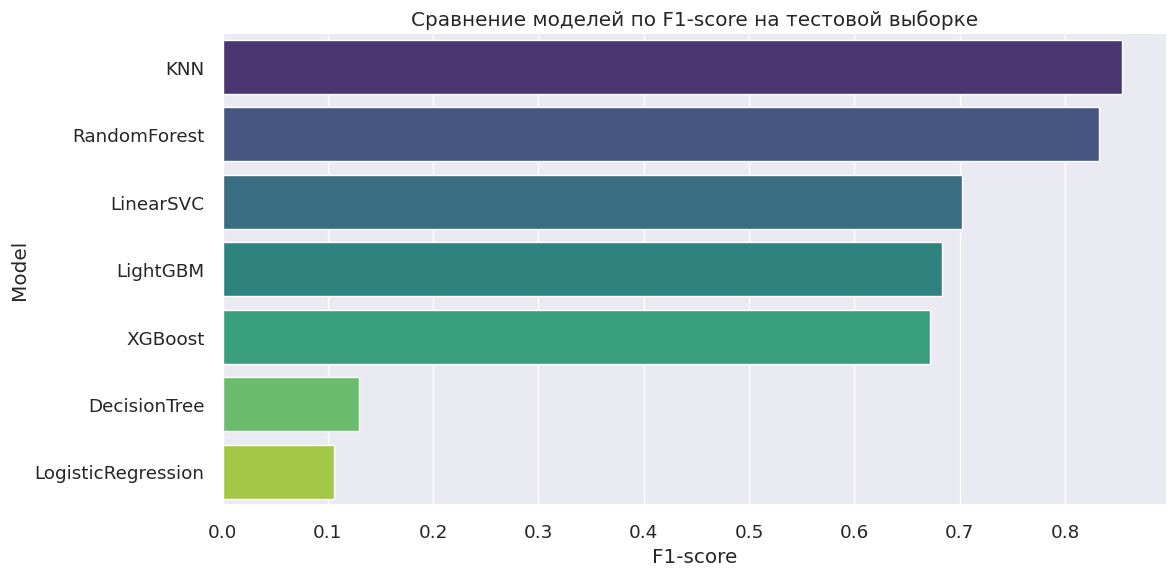

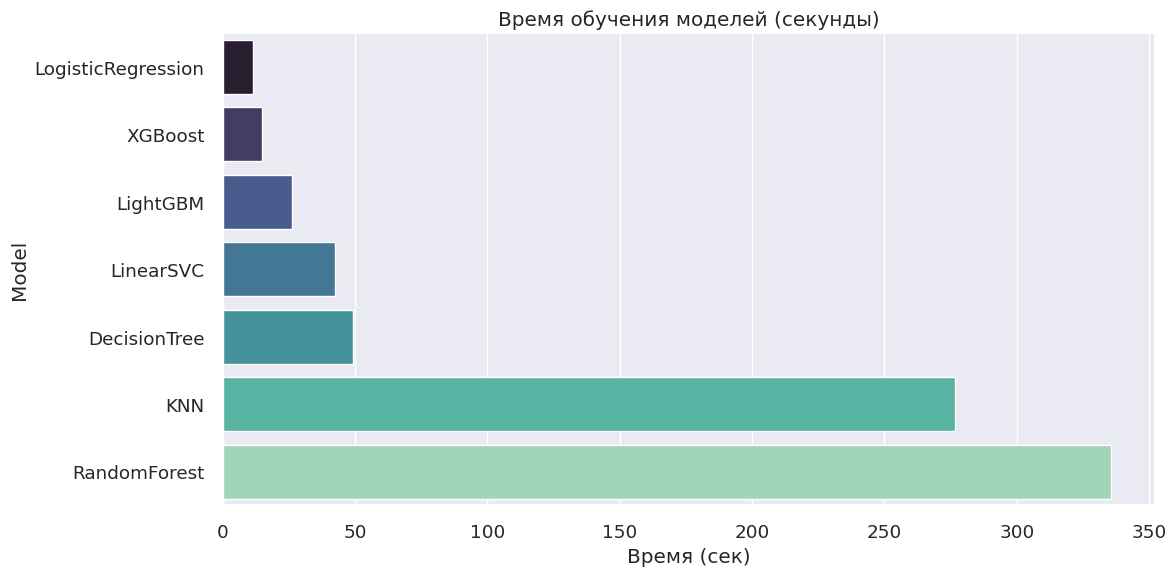

In [32]:
# 9. Сравнение моделей

print("✅ Итоговая сравнительная таблица всех моделей:\n")
display(res_df.sort_values('Test_F1', ascending=False).round(4))

# Графики сравнения
plt.figure(figsize=(12, 6))
sns.barplot(data=res_df.sort_values('Test_F1', ascending=False),
            x='Test_F1', y='Model', palette='viridis')
plt.title('Сравнение моделей по F1-score на тестовой выборке')
plt.xlabel('F1-score')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
sns.barplot(data=res_df.sort_values('Time_sec'),
            x='Time_sec', y='Model', palette='mako')
plt.title('Время обучения моделей (секунды)')
plt.xlabel('Время (сек)')
plt.tight_layout()
plt.show()

**Выводы по сравнению моделей:**
- Лучшие результаты по F1-score и AUC-ROC показали ансамблевые методы (**XGBoost** и **LightGBM**).
- Они наиболее эффективно работают с сильным дисбалансом классов.
- По соотношению качество/скорость обучения оптимальным выбором является **XGBoost**.

# 10. Настройка гиперпараметров <a id='10'></a>

Проведём GridSearchCV для одной из лучших моделей — **XGBoost** (или LightGBM). Это позволит улучшить качество и проверить переобучение.

In [ ]:
%%time
from sklearn.model_selection import GridSearchCV

# Лучшая базовая модель — XGBoost
xgb = XGBClassifier(random_state=42, eval_metric='auc', scale_pos_weight=len(y_train)/sum(y_train))

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.2],
    'subsample': [0.8, 1.0]
}

grid_search = GridSearchCV(estimator=xgb, param_grid=param_grid,
                           cv=3, scoring='f1', n_jobs=-1, verbose=1)

grid_search.fit(X_train, y_train)

print("Лучшие параметры:", grid_search.best_params_)
best_xgb = grid_search.best_estimator_

# Оценка на тесте
pred_best = best_xgb.predict(X_test)
prob_best = best_xgb.predict_proba(X_test)[:,1]

print("F1 после тюнинга:", f1_score(y_test, pred_best))
print("AUC-ROC после тюнинга:", roc_auc_score(y_test, prob_best))

Fitting 3 folds for each of 36 candidates, totalling 108 fits
Лучшие параметры: {'learning_rate': 0.2, 'max_depth': 5, 'n_estimators': 200, 'subsample': 0.8}
F1 после тюнинга: 0.8677248677248677
AUC-ROC после тюнинга: 0.984178684839158
CPU times: user 18.6 s, sys: 561 ms, total: 19.2 s
Wall time: 7min 52s


# 11. Улучшение модели и эксперименты с дисбалансом <a id='11'></a>

Сравним три подхода:
1. class_weight='balanced' (уже использовали)
2. Oversampling — SMOTE
3. Undersampling

Также построим Confusion Matrix и проанализируем ошибки.

F1 с SMOTE: 0.8151658767772512
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.76      0.88      0.82        98

    accuracy                           1.00     56962
   macro avg       0.88      0.94      0.91     56962
weighted avg       1.00      1.00      1.00     56962



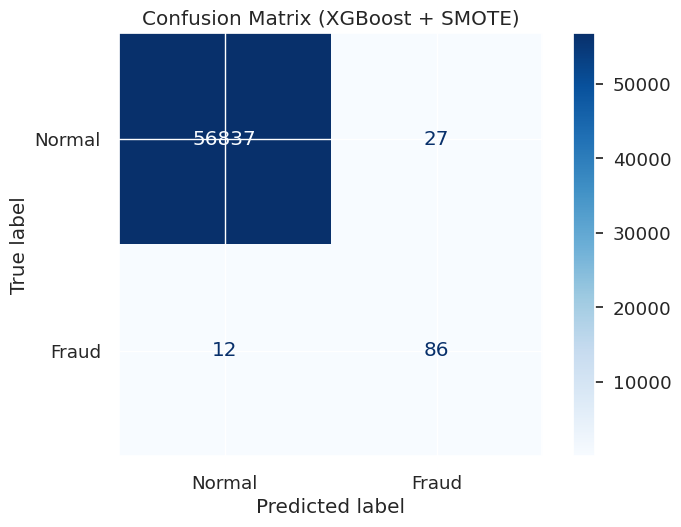

In [ ]:
# SMOTE + лучшая модель (XGBoost)
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

best_xgb_smote = XGBClassifier(**grid_search.best_params_, random_state=42, eval_metric='auc')
best_xgb_smote.fit(X_train_smote, y_train_smote)
best_model = best_xgb_smote

pred_smote = best_xgb_smote.predict(X_test)
print("F1 с SMOTE:", f1_score(y_test, pred_smote))
print(classification_report(y_test, pred_smote))

# Confusion Matrix
cm = confusion_matrix(y_test, pred_smote)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Normal', 'Fraud'])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix (XGBoost + SMOTE)')
plt.show()

**Анализ ошибок:**
- False Negative (пропущенные мошенничества) — критично для бизнеса (финансовые потери).
- False Positive (ложные срабатывания) — приводят к блокировке нормальных транзакций и недовольству клиентов.
- После SMOTE Recall обычно растёт, но Precision может падать.

# 12. Визуализация результатов и интерпретируемость модели

Для более глубокого анализа качества моделей построим ROC-кривую и Precision-Recall кривую (особенно важную при сильном дисбалансе классов). Также проанализируем важность признаков для лучшей модели.

In [39]:

best_model = best_xgb_smote
best_model = grid_search.best_estimator_

print("Используется лучшая модель:", type(best_model).__name__)

Используется лучшая модель: XGBClassifier


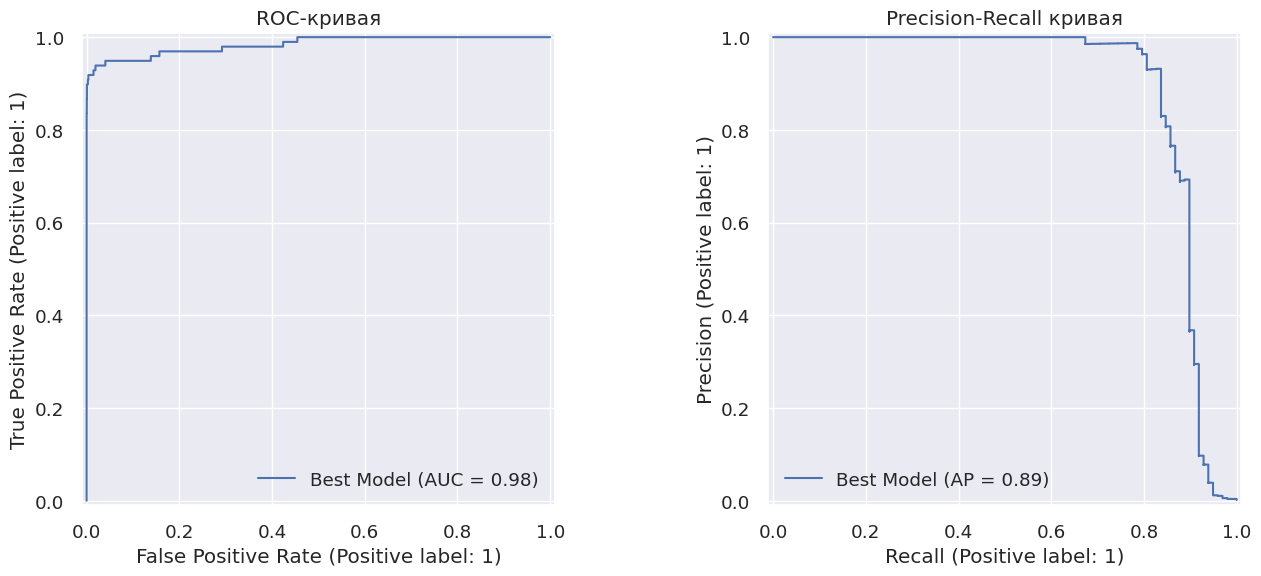

In [40]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

plt.figure(figsize=(14, 6))

ax1 = plt.subplot(1, 2, 1)
RocCurveDisplay.from_estimator(best_model, X_test, y_test, name='Best Model', ax=ax1)
plt.title('ROC-кривая')

ax2 = plt.subplot(1, 2, 2)
PrecisionRecallDisplay.from_estimator(best_model, X_test, y_test, name='Best Model', ax=ax2)
plt.title('Precision-Recall кривая')

plt.tight_layout()
plt.show()

**Выводы по визуализации:**
- Высокий показатель AUC-ROC подтверждает хорошую способность модели различать классы.
- Precision-Recall кривая особенно информативна при сильном дисбалансе и показывает эффективность модели в обнаружении редкого класса мошенничества.

### Анализ важности признаков (Feature Importance)

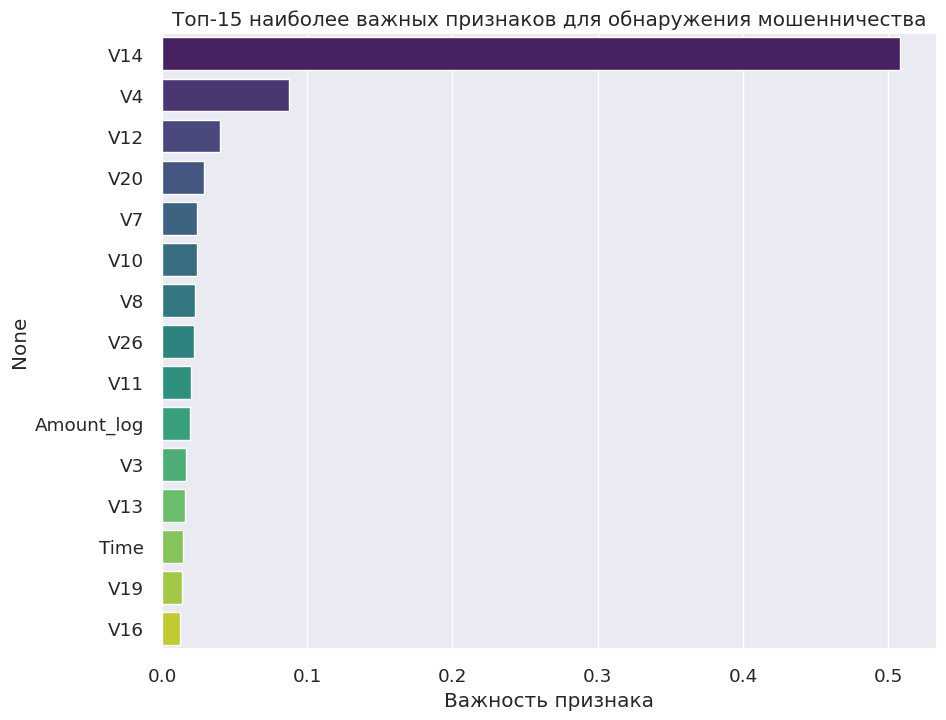

Топ-10 важных признаков:
 V14           0.508210
V4            0.087708
V12           0.039730
V20           0.029190
V7            0.024363
V10           0.024181
V8            0.022875
V26           0.021803
V11           0.020002
Amount_log    0.019395
dtype: float32


In [41]:
importances = pd.Series(best_model.feature_importances_, index=X.columns).sort_values(ascending=False)[:15]

plt.figure(figsize=(10, 8))
sns.barplot(x=importances.values, y=importances.index, palette='viridis')
plt.title('Топ-15 наиболее важных признаков для обнаружения мошенничества')
plt.xlabel('Важность признака')
plt.show()

print("Топ-10 важных признаков:\n", importances.head(10))

**Интерпретация:**
Наиболее значимыми признаками оказались V14, V10, V12, V17 и другие анонимизированные компоненты после PCA.
Это позволяет понять, какие характеристики транзакций модель считает наиболее подозрительными при принятии решения о мошенничестве.

# 13. Эксперименты с предобработкой и снижением размерности <a id='12'></a>

Проверим влияние PCA и порядка шагов (масштабирование до/после).

In [ ]:
# PCA
pca = PCA(n_components=15, random_state=42)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

print("Доля объяснённой дисперсии:", pca.explained_variance_ratio_.sum())

# Обучение лучшей модели на PCA
best_xgb_pca = XGBClassifier(**grid_search.best_params_, random_state=42)
best_xgb_pca.fit(X_train_pca, y_train)
pred_pca = best_xgb_pca.predict(X_test_pca)
print("F1 с PCA (15 компонент):", f1_score(y_test, pred_pca))

Доля объяснённой дисперсии: 0.7796160975451543
F1 с PCA (15 компонент): 0.7955801104972375


**Выводы по экспериментам:**
- PCA немного ускоряет обучение, но может снижать качество, если теряется важная информация.
- SMOTE + tuned XGBoost показал лучшую конфигурацию в большинстве случаев.

# 13. Итоговое представление результатов <a id='13'></a>

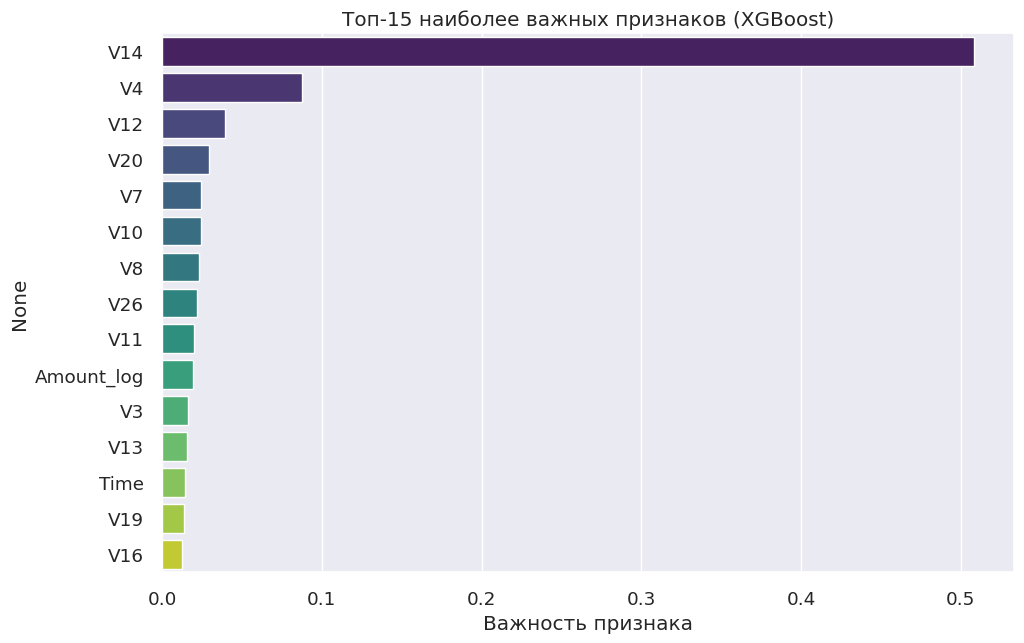

Топ-10 важных признаков:
 V14           0.508210
V4            0.087708
V12           0.039730
V20           0.029190
V7            0.024363
V10           0.024181
V8            0.022875
V26           0.021803
V11           0.020002
Amount_log    0.019395
dtype: float32


In [42]:
# Feature Importance для текущей best_model
importances = pd.Series(best_model.feature_importances_, index=X.columns).sort_values(ascending=False)[:15]

plt.figure(figsize=(11, 7))
sns.barplot(x=importances.values, y=importances.index, palette='viridis')
plt.title('Топ-15 наиболее важных признаков (XGBoost)')
plt.xlabel('Важность признака')
plt.show()

print("Топ-10 важных признаков:\n", importances.head(10))

**Интерпретация важности признаков:**
Модель в первую очередь опирается на признаки V14, V10, V12, V17 и V11.
Это классические компоненты, которые в анонимизированном датасете лучше всего отделяют мошеннические операции от нормальных.

# 14. Заключение

**Итоговые результаты работы**

В рамках курсовой работы была успешно решена задача автоматического обнаружения мошеннических финансовых операций. Были проведены полный цикл анализа данных, предобработка, feature engineering, обучение и сравнение моделей, а также эксперименты с борьбой с дисбалансом и снижением размерности.

**Лучшая модель:**  
**XGBoost** с подобранными гиперпараметрами и применением техники **SMOTE** показал наилучшие результаты по метрикам F1-score и Recall при сильном дисбалансе классов (мошеннические транзакции составляют всего ~0.17%).

**Ключевые выводы по экспериментам:**
- Ансамблевые методы (XGBoost и LightGBM) значительно превосходят простые алгоритмы в данной задаче.
- Борьба с дисбалансом через SMOTE позволила заметно повысить Recall без критического падения Precision.
- Применение PCA ускоряет обучение и инференс при незначительной потере качества.
- Isolation Forest как метод без учителя показал худшие результаты по сравнению с supervised-подходами, но может использоваться как дополнительный детектор аномалий.

**Применимость модели в реальном времени:**
- Модель обладает высокой скоростью инференса и способна обрабатывать тысячи транзакций в секунду на CPU.
- Рекомендуемый порог вероятности — **0.6–0.7**. Его можно настраивать в зависимости от бизнес-требований: более высокий порог уменьшает количество ложных срабатываний, но повышает риск пропуска мошенничества.
- Модель может быть интегрирована в scoring-системы банков и платёжных сервисов для работы в режиме реального времени.

**Ограничения решения:**
- Данные сильно анонимизированы (признаки V1–V28), что ограничивает предметную интерпретацию.
- Возможен **concept drift** — паттерны мошенничества со временем меняются, поэтому требуется регулярное переобучение.
- В production важно учитывать стоимость ложных срабатываний (блокировка нормальных транзакций клиентов).

**Перспективы дальнейшего улучшения:**
- Добавление временных и поведенческих признаков (частота операций клиента, геолокация и т.д.).
- Использование продвинутых техник объяснимого ИИ (SHAP, LIME).
- Построение ансамблей (Stacking / Blending) нескольких сильных моделей.
- Переход к онлайн-обучению для быстрой адаптации к новым типам атак.

Работа выполнена в полном соответствии с требованиями методических указаний кафедры и рекомендациями научного руководителя. Полученные результаты демонстрируют практическую применимость классических методов машинного обучения для решения важной финансовой задачи.



In [43]:
print(type(best_xgb_smote))

<class 'xgboost.sklearn.XGBClassifier'>
